In [35]:
# Kendi çalışma notu: Model karşılaştırmasında aynı test bölümünü kullan.
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.metrics import (confusion_matrix,ConfusionMatrixDisplay,accuracy_score,precision_score,
recall_score,f1_score,classification_report,roc_curve,roc_auc_score)

#### Regresyon: housing.csv

In [36]:
df = pd.read_csv("housing.csv")
df.head(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY


#### Veri seti hakkında bilgiler edinelim

In [37]:
print("Veri seti boyutu: ", df.shape)
df.info()

Veri seti boyutu:  (20640, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [38]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

#### eksik veriyi dolduralım

In [39]:
df["total_bedrooms"] = df["total_bedrooms"].fillna(df["total_bedrooms"].median())
print("Kalan eksik veri:", df.isnull().sum().sum())

Kalan eksik veri: 0


In [40]:
df["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

#### One hot encoding yapalım

In [41]:
df_encoded = pd.get_dummies(df,columns=["ocean_proximity"],drop_first=True,dtype=int)
df_encoded.head(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,1,0


#### Değişkenleri belirleyelim

In [42]:
X = df_encoded.drop(columns=["median_house_value"])
y = df_encoded["median_house_value"]

#### Train - test'i split edelim

In [43]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

#### linear regresyon

In [44]:
model = LinearRegression()
model.fit(X_train,y_train)
model_pred = model.predict(X_test)

In [45]:
r2_lin = r2_score(y_test,model_pred)
print("R-squared değeri (Linear):", r2_lin)
mae_lin = mean_absolute_error(y_test,model_pred)
print("Ortalama Mutlak Hata (MAE):", mae_lin)
rmse_lin = np.sqrt(mean_squared_error(y_test,model_pred))
print("Kök Ortalama Kare Hata (RMSE):", rmse_lin)

R-squared değeri (Linear): 0.6254240620553604
Ortalama Mutlak Hata (MAE): 50670.73824097212
Kök Ortalama Kare Hata (RMSE): 70060.52184473521


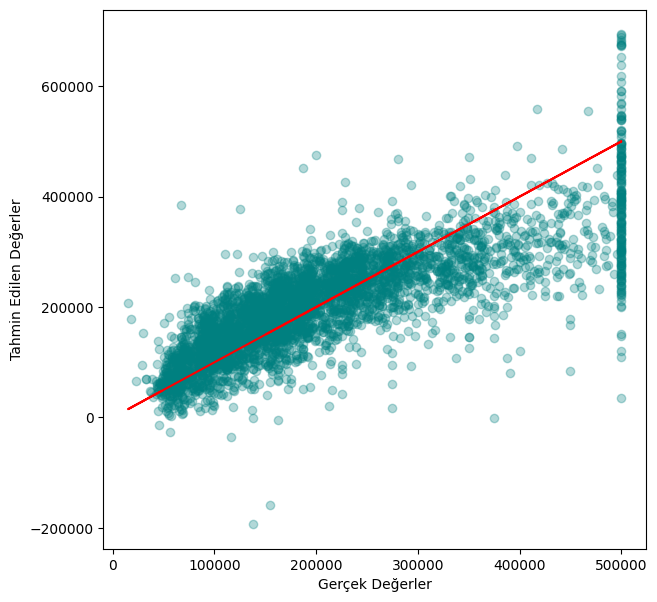

In [46]:
plt.figure(figsize=(7,7))
plt.scatter(y_test,model_pred,alpha=0.3,color="teal")
plt.plot(y_test,y_test,"r")
plt.xlabel("Gerçek Değerler")
plt.ylabel("Tahmin Edilen Değerler")
plt.show()

#### polinom regresyon tek değişkenle

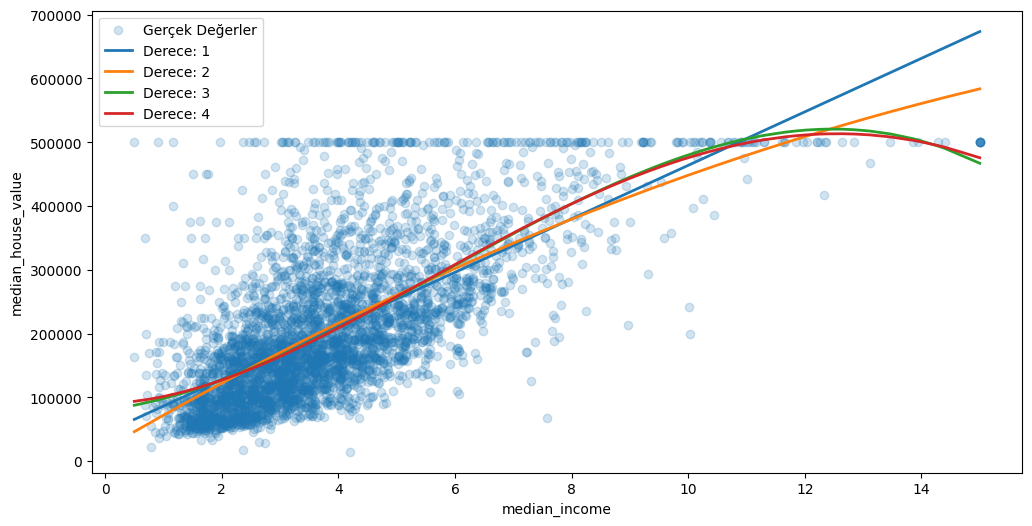

,R2,RMSE
Derece,,
1,0.458859,84209.012414
2,0.463318,83861.389691
3,0.467116,83564.135519
4,0.467262,83552.632777


In [47]:
degrees = [1,2,3,4]
poly_results = {}

X_one_train = X_train[["median_income"]]
X_one_test = X_test[["median_income"]]
x_sorted = pd.DataFrame({"median_income":np.sort(X_one_test["median_income"].values)})

plt.figure(figsize=(12,6))
plt.scatter(X_one_test["median_income"],y_test,alpha=0.2,color="#1f77b4",label="Gerçek Değerler")
for degree in degrees:
    model_poly = make_pipeline(PolynomialFeatures(degree),LinearRegression())
    model_poly.fit(X_one_train,y_train)
    poly_pred = model_poly.predict(X_one_test)
    poly_results[degree] = {
        "R2": r2_score(y_test,poly_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test,poly_pred))
    }
    plt.plot(x_sorted["median_income"],model_poly.predict(x_sorted),linewidth=2,label=f"Derece: {degree}")
plt.xlabel("median_income")
plt.ylabel("median_house_value")
plt.legend()
plt.show()

pd.DataFrame(poly_results).T.rename_axis("Derece")

#### polinom regresyon tüm değişkenlerle

In [48]:
poly_multi_model = make_pipeline(PolynomialFeatures(degree=2,include_bias=False),StandardScaler(),LinearRegression())
poly_multi_model.fit(X_train,y_train)
poly_multi_pred = poly_multi_model.predict(X_test)

r2_poly = r2_score(y_test,poly_multi_pred)
print("R-squared değeri (Polinom):", r2_poly)
mae_poly = mean_absolute_error(y_test,poly_multi_pred)
print("Ortalama Mutlak Hata (MAE):", mae_poly)
rmse_poly = np.sqrt(mean_squared_error(y_test,poly_multi_pred))
print("Kök Ortalama Kare Hata (RMSE):", rmse_poly)

R-squared değeri (Polinom): 0.6555665135152371
Ortalama Mutlak Hata (MAE): 46398.84548959221
Kök Ortalama Kare Hata (RMSE): 67182.49274152076


In [49]:
pd.DataFrame({
    "Linear": [r2_lin,mae_lin,rmse_lin],
    "Polinom": [r2_poly,mae_poly,rmse_poly]
},index=["R2","MAE","RMSE"])

,Linear,Polinom
R2,0.625424,0.655567
MAE,50670.738241,46398.845490
RMSE,70060.521845,67182.492742


#### Sınıflandırma: processed.cleveland.data

In [50]:
column_names = ["age","sex","cp","trestbps","chol","fbs","restecg",
                "thalach","exang","oldpeak","slope","ca","thal","target"]
df_heart = pd.read_csv("processed.cleveland.data",header=None,names=column_names,na_values="?")
df_heart.head(2)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2


In [51]:
print("Veri seti boyutu: ", df_heart.shape)
df_heart.isnull().sum()

Veri seti boyutu:  (303, 14)


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

#### eksikleri atalım, hedefi 0/1 yapalım

In [52]:
df_heart = df_heart.dropna()
df_heart["disease"] = (df_heart["target"]>0).astype(int)
df_heart = df_heart.drop(columns=["target"])
df_heart["disease"].value_counts(normalize=True).rename(index={0:"Sağlıklı",1:"Hasta"})

disease
Sağlıklı    0.538721
Hasta       0.461279
Name: proportion, dtype: float64

#### One hot encoding yapalım

In [53]:
df_heart_encoded = pd.get_dummies(df_heart,columns=["cp","restecg","slope","thal"],drop_first=True,dtype=int)
df_heart_encoded.head(2)

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,disease,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0,slope_2.0,slope_3.0,thal_6.0,thal_7.0
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,0,0,0,0,0,1,0,1,1,0
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,1,0,0,1,0,1,1,0,0,0


#### Değişkenleri belirleyip split edelim

In [54]:
X = df_heart_encoded.drop(columns=["disease"])
y = df_heart_encoded["disease"]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

#### scale edelim

In [55]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### logistic regresyon

In [56]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled,y_train)

y_proba = log_reg.predict_proba(X_test_scaled)[:,1]
y_pred = log_reg.predict(X_test_scaled)

pd.DataFrame({
    "Gerçek": y_test.values[:10],
    "Tahmin": y_pred[:10],
    "Olasılık": y_proba[:10].round(2)
})

,Gerçek,Tahmin,Olasılık
0,0,0,0.03
1,0,0,0.06
2,0,1,0.54
3,0,0,0.25
4,0,0,0.36
5,0,0,0.01
6,1,1,0.82
7,0,0,0.07
8,1,0,0.28
9,0,0,0.06


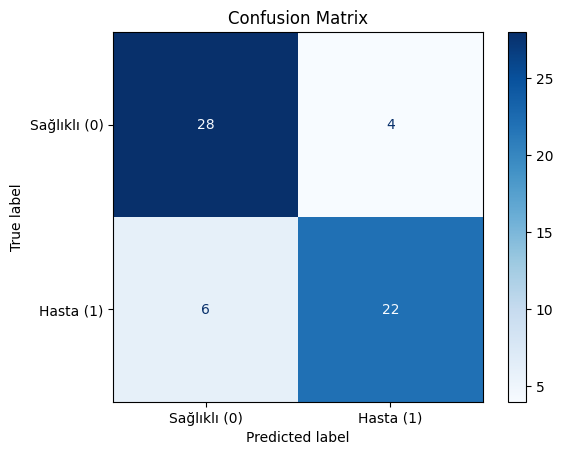

In [57]:
cm = confusion_matrix(y_test,y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Sağlıklı (0)","Hasta (1)"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

In [58]:
print("Accuracy:", accuracy_score(y_test,y_pred))
print("Precision:", precision_score(y_test,y_pred))
print("Recall:", recall_score(y_test,y_pred))
print("F1 Score:", f1_score(y_test,y_pred))
print("AUC:", roc_auc_score(y_test,y_proba))
print(classification_report(y_test,y_pred))

Accuracy: 0.8333333333333334
Precision: 0.8461538461538461
Recall: 0.7857142857142857
F1 Score: 0.8148148148148148
AUC: 0.9497767857142857
              precision    recall  f1-score   support

           0       0.82      0.88      0.85        32
           1       0.85      0.79      0.81        28

    accuracy                           0.83        60
   macro avg       0.83      0.83      0.83        60
weighted avg       0.83      0.83      0.83        60



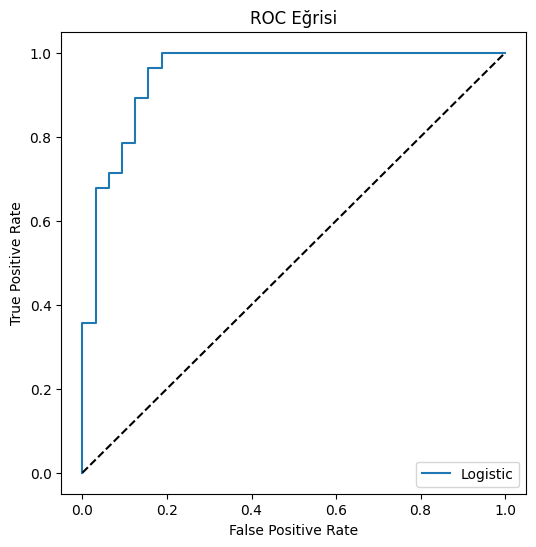

In [59]:
fpr,tpr,_ = roc_curve(y_test,y_proba)
plt.figure(figsize=(6,6))
plt.plot(fpr,tpr,label="Logistic")
plt.plot([0,1],[0,1],"k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Eğrisi")
plt.legend()
plt.show()

### Çalışma değerlendirmesi

ROC eğrisi farklı eşiklerdeki duyarlılık ve yanlış pozitif oranını birlikte gösterir.


### Ek değerlendirme: karar eşiği

**Amaç:** Aynı olasılık tahmininden farklı eşiklerle elde edilen precision ve recall değerlerini karşılaştırmak.

**Yorum:** Eşik düşerse daha çok pozitif tahmin elde edilir; bunun yanlış pozitif sayısını da artırıp artırmadığı matriste kontrol edilmelidir.

In [ ]:
from sklearn.metrics import precision_score, recall_score

esik_sonuclari = []
for esik in (0.3, 0.5, 0.7):
    tahmin = (y_proba >= esik).astype(int)
    esik_sonuclari.append({"Eşik": esik,
                          "Precision": precision_score(y_test, tahmin, zero_division=0),
                          "Recall": recall_score(y_test, tahmin, zero_division=0)})
print(pd.DataFrame(esik_sonuclari).round(3).to_string(index=False))